# Hotel Booking Cancellation Analysis
## Project Overview
The project analysis hotel booking data helps understand the characteristics associated with booking cancellations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
df = pd.read_csv('D:\Python for Data Analysis\Hotel Data Analysis\hotel_bookings.csv')
#Preview data 
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [5]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [6]:
# shape of the data
df.shape

(119390, 32)

Database has 119390 rows and 32 columns

In [7]:
# Check for missing values
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [8]:
## Data Cleaning

## Data Cleaning

In [9]:
# Fill company and agent with 0 (indicating booked directly)
df['agent'] = df['agent'].fillna(0)
df['company'] = df['company'].fillna(0)


In [10]:
# fill children column 0(0 indicating no children)
df['children'] = df['children'].fillna(0)


In [11]:
# drop th rest of the missing values
df = df.dropna()


In [12]:
#drop duplicates
df = df.drop_duplicates()

In [13]:
# Recheck the shape
df.shape

(86944, 32)

In [14]:
#rechect for missing values
df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

In [15]:
#recheck for the duplicates
df.duplicated().sum()

np.int64(0)

## Feature Engineering

In [16]:
# Calculate total nights
df['total nights'] = df['stays_in_week_nights'] + df['stays_in_weekend_nights']

In [17]:
#Calculatre total guests
df['total_guests'] = df['adults'] + df['children']+ df['babies']

In [18]:
# Create 'is_family'(True if there are children or babies, False if otherwise)
df['is_family'] = (df['children']>0) | (df['babies']>0)

In [19]:
#create 'season' based on arrival month
month_to_season = {
    'December': 'Winter', 'January': 'Winter', 'February': 'Winter', 'March': 'Spring',
    'April': 'Spring', 'May': 'Spring', 'June': 'Summer', 'July': 'Summer', 'August': 'Summer',
    'September': 'Fall', 'October': 'Fall', 'November': 'Fall'
}
df['season'] = df ['arrival_date_month'].map(month_to_season)


In [20]:
#Preview the data
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total nights,total_guests,is_family,season
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,0,2.0,False,Summer
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,0,2.0,False,Summer
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,1,1.0,False,Summer
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,1,1.0,False,Summer
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Transient,98.0,0,1,Check-Out,2015-07-03,2,2.0,False,Summer


In [29]:
# Export Cleaned Data
df.to_csv('Cleaned_hotel_bookings.csv', index = False)

## Exploratory Data Analysis (EDA)


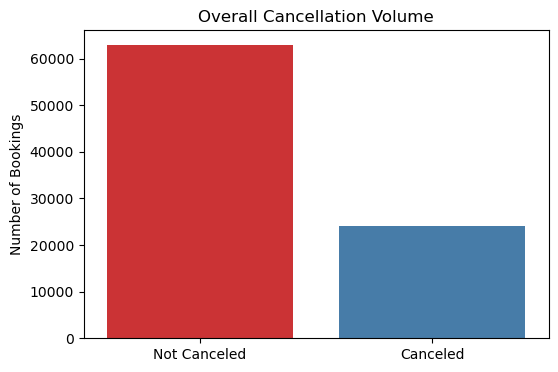

Overall Cancellation Rate: 27.6)%


In [21]:
# overall overall cancellation distribution
plt.figure(figsize =(6,4))
df['is_canceled_label'] = df['is_canceled'].map({0: 'Not Canceled',1: 'Canceled'})

sns.countplot(data=df, x='is_canceled_label', hue ='is_canceled_label', palette = 'Set1', legend = False)
plt.title('Overall Cancellation Volume')
plt.ylabel('Number of Bookings')
plt.xlabel('')
plt.savefig('cancellation.png')
plt.show()

# Calculate the overall cancelation rate
cancel_pct = df['is_canceled'].value_counts(normalize = True) * 100
print(f'Overall Cancellation Rate: {cancel_pct[1]:.1f})%')

The cancellation rate is 27.6%, implying that 1 in 3 bookings is canceled. Thus, the hotels cannot rely on the initial booking numbers for staffing or food ordering. Management must utilize an overbooking strategy to ensure the hotel is full on any given night

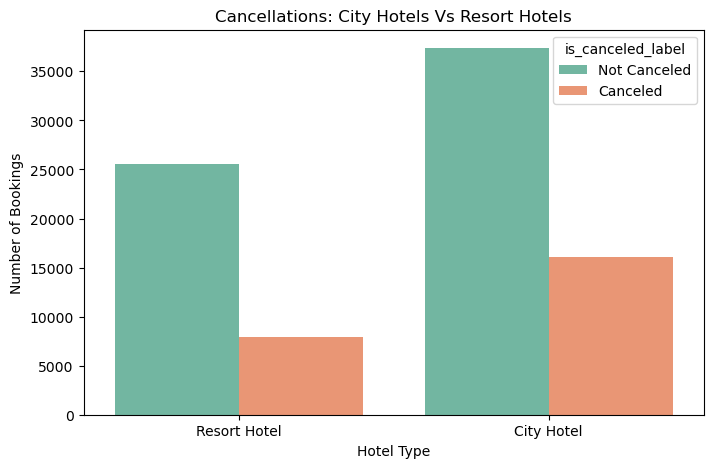

hotel         is_canceled
City Hotel    0              69.965557
              1              30.034443
Resort Hotel  0              76.296164
              1              23.703836
Name: proportion, dtype: float64

In [28]:
# Hotel type comparison
#Does the hotel type affect the likelihood of cancelations?
# we will compare the city hotels to resort hotels to see if their customer bases behave differently.
plt.figure(figsize=(8,5))
sns.countplot(x='hotel', hue = 'is_canceled_label',data=df,palette = 'Set2')
plt.title('Cancellations: City Hotels Vs Resort Hotels')
plt.ylabel('Number of Bookings')
plt.xlabel('Hotel Type')
plt.savefig('hoteltype.png')
plt.show()

#Calculate rates per hotel type

df.groupby('hotel')['is_canceled'].value_counts(normalize=True)*100

City hotels see significantly higher bookings in volumes and a much higher cancellation rates than resort hotels. City trips are often short, impulsive or tied to business meetings that get moved.Resort trips are usually planned(often) involve flights making guests less likely to cancel.


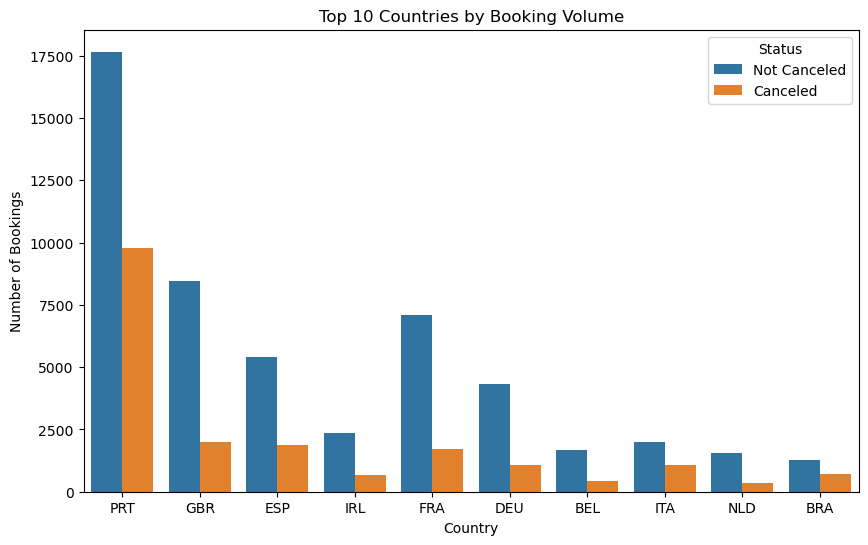

In [23]:
# Understanding the geographical origin of our customers how does affect the cancellations?
plt.figure(figsize=(10,6))
#top 10 countries by volume
top_10_countries = df['country'].value_counts().head(10).index
sns.countplot(x='country', hue = 'is_canceled_label', data = df[df['country'].isin(top_10_countries)])
plt.title('Top 10 Countries by Booking Volume')
plt.ylabel('Number of Bookings')
plt.xlabel('Country')
plt.legend(title = 'Status')
plt.savefig('countries.png')
plt.show()

PRT (Portugal) generate the highest booking volume of bookings, but it also has a staggering cancellation rate. Becaause the hotels in this dataset are located in portugal, these are local residents. Locals often book multiple hotels as 'backups' for weekend gateways because they don't have to commit to flights.

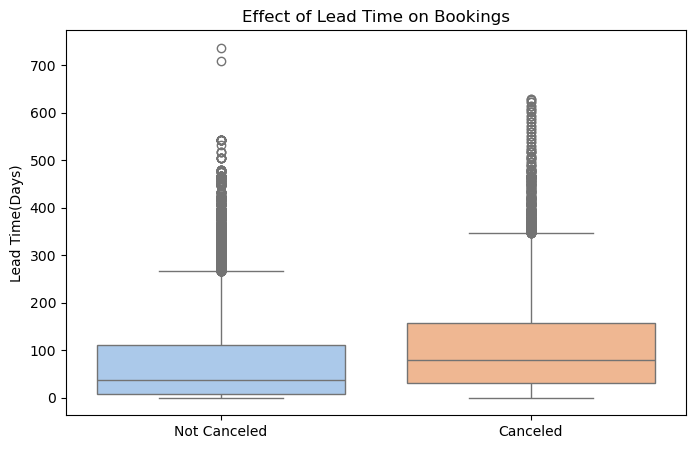

In [24]:
# Lead Time Analysis leadtime is the number of days between when
# the guest books and whey arrive,
plt.figure(figsize = (8,5))
sns.boxplot(x='is_canceled_label', y = 'lead_time', data = df, hue = 'is_canceled_label', palette = 'pastel', legend = False)
plt.title('Effect of Lead Time on Bookings')
plt.ylabel('Lead Time(Days)')
plt.xlabel('')
plt.savefig('leadtime.png')
plt.show()

The median lead time for canceled bookings is much higher. Simply put: the earlier someone books the more time they have to change their mind and cancel, find a better deal, or experience a schedule change.

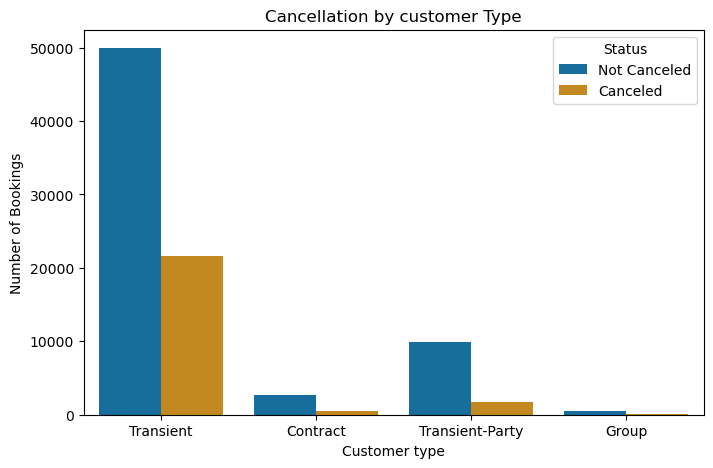

In [25]:
# Customer Type Analysis
# are solo/transceint traveller more volatile than larger groups or corporate contracts?
plt.figure(figsize=(8,5))
sns.countplot(x='customer_type', hue = 'is_canceled_label', data=df, palette = 'colorblind')
plt.title('Cancellation by customer Type')
plt.ylabel('Number of Bookings')
plt.xlabel('Customer type')
plt.legend(title = 'Status')
plt.savefig('customertype.png')
plt.show()

Transient travelers(Independent travelers not part of a group) account for the vast majority of both bookings and cancelations. Conversely, 'Groups' and 'Contract' bookings are much more stable. Recommendation: The sales team should prioritize securing more B2B (Business to Business) contracts and group events to build a stable, guaranteed revenue base that protects against volatility of individual transients.

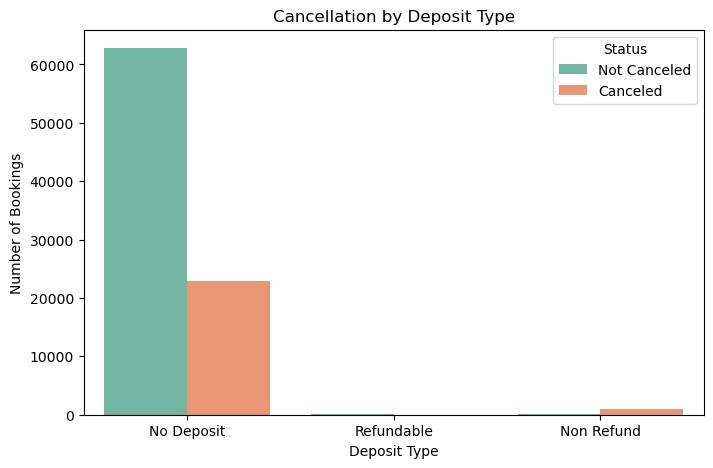

In [26]:
# Impact of deposit type on cancellations
plt.figure(figsize=(8,5))
sns.countplot(x='deposit_type', hue = 'is_canceled_label', data=df, palette = 'Set2')
plt.title('Cancellation by Deposit Type')
plt.ylabel('Number of Bookings')
plt.xlabel('Deposit Type')
plt.legend(title='Status')
plt.savefig('deposittype.png')
plt.show()

Majority of the books have no deposit. Management should impelement a compulsory and non-refundable deposit approach to minimize volativity.

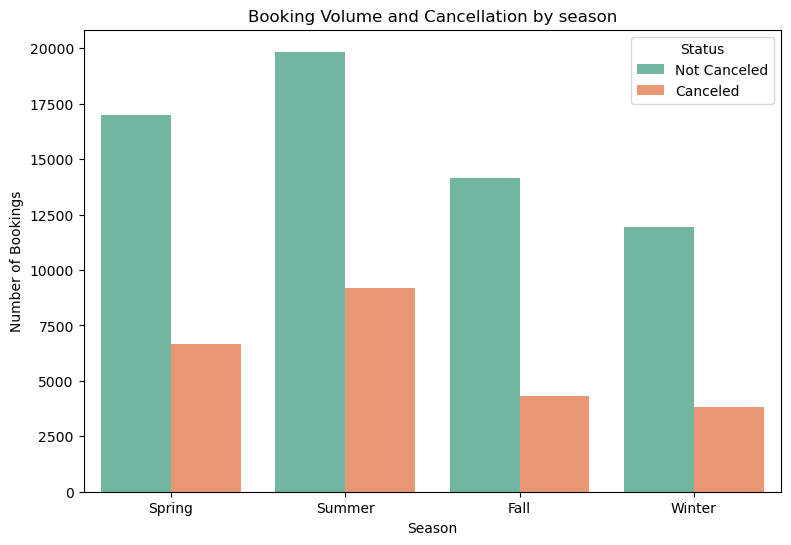

In [27]:
# Seasonal Cancellation analysis
plt.figure(figsize=(9,6))

# Define seasonal order
season_order =['Spring', 'Summer', 'Fall', 'Winter']
sns.countplot(x='season', hue = 'is_canceled_label', data=df, order=season_order, palette = 'Set2')
plt.title('Booking Volume and Cancellation by season')
plt.ylabel('Number of Bookings')
plt.xlabel('Season')
plt.legend(title='Status')
plt.savefig('seasonal.png')
plt.show()